# DS605 Lab07:PCA

### Part A: Image Representation and Dataset Construction

The objective of this part is to represent face images numerically so that machine learning algorithms can process them.

We load the grayscale images, inspect their dimensions and pixel intensity values, and flatten each image into a one-dimensional feature vector. We then combine the vectors into a feature matrix `X` and create a label array `y` containing the corresponding subject identities.

Finally, we divide the dataset into training and testing sets using a reproducible, stratified split so that images from every subject appear in both sets.

In [1]:
from pathlib import Path
import zipfile
import re

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

DATA_ZIP = Path("archive.zip")
EXTRACT_DIR = Path("orl_faces_data")

if DATA_ZIP.exists():
    EXTRACT_DIR.mkdir(exist_ok=True)

    with zipfile.ZipFile(DATA_ZIP, "r") as zf:
        zf.extractall(EXTRACT_DIR)

    SEARCH_ROOT = EXTRACT_DIR
else:
    SEARCH_ROOT = Path(".")

# Locate subject folders such as s1, s2, ..., s40
subject_dirs = [
    folder for folder in SEARCH_ROOT.iterdir()
    if folder.is_dir() and re.fullmatch(r"s\d+", folder.name)
]

subject_dirs = sorted(
    subject_dirs,
    key=lambda folder: int(folder.name[1:])
)

if not subject_dirs:
    raise FileNotFoundError(
        "Subject folders were not found. "
        "Place archive.zip beside the notebook."
    )

images = []
labels = []
image_paths = []
image_shape = None

for folder in subject_dirs:
    subject_id = int(folder.name[1:])

    files = sorted(
        folder.glob("*.pgm"),
        key=lambda path: int(path.stem)
    )

    for path in files:
        with Image.open(path) as image:
            grayscale = image.convert("L")
            pixels = np.asarray(grayscale, dtype=np.float64)

        if image_shape is None:
            image_shape = pixels.shape

        if pixels.shape != image_shape:
            raise ValueError(f"Unexpected image dimensions: {path}")

        images.append(pixels.flatten())
        labels.append(subject_id)
        image_paths.append(path)

X = np.vstack(images)
y = np.asarray(labels)

print("Total images:", X.shape[0])
print("Number of subjects:", len(np.unique(y)))
print("Image dimensions:", image_shape)
print("Features per image:", X.shape[1])
print("Pixel intensity range:", X.min(), "to", X.max())
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)

Total images: 400
Number of subjects: 40
Image dimensions: (112, 92)
Features per image: 10304
Pixel intensity range: 0.0 to 251.0
Feature matrix shape: (400, 10304)
Label array shape: (400,)


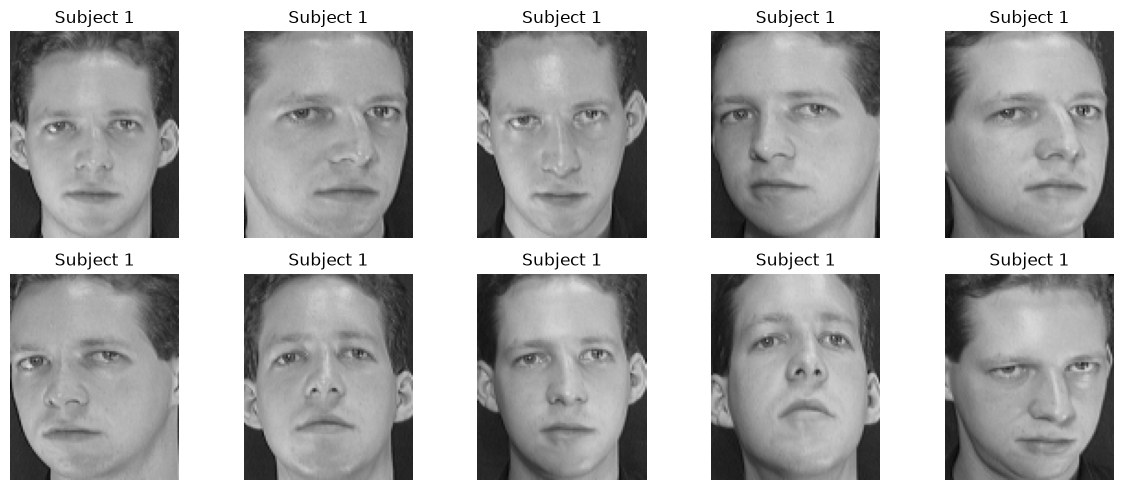

First 20 pixel values:
[48. 49. 45. 47. 49. 57. 39. 42. 53. 49. 53. 60. 76. 91. 99. 95. 80. 75.
 66. 54.]


In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(
        X[i].reshape(image_shape),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("First 20 pixel values:")
print(X[0, :20])

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print(
    "Subjects in training:",
    len(np.unique(y_train))
)

print(
    "Subjects in testing:",
    len(np.unique(y_test))
)

assert set(np.unique(y_train)) == set(np.unique(y_test))

Training features: (320, 10304)
Testing features: (80, 10304)
Training labels: (320,)
Testing labels: (80,)
Subjects in training: 40
Subjects in testing: 40


# Part B: Principal Component Analysis (PCA)

The objective of this part is to reduce the dimensionality of the face-image representation while retaining the most important variation in the training data.

First, we calculate the mean face from the training images and center the data by subtracting this mean. Next, we implement PCA using NumPy's Singular Value Decomposition (SVD), calculate explained variance, and determine the minimum number of principal components required to retain at least 90% of the training variance.

Finally, we use eigen-decomposition as an alternative mathematical approach and compare its principal directions and eigenvalues with those obtained through SVD.

PCA is implemented using NumPy linear algebra, as required by the assignment. The test images are transformed using the mean and principal directions learned from the training set.

Mean face shape: (10304,)
Centered training shape: (320, 10304)
Centered testing shape: (80, 10304)


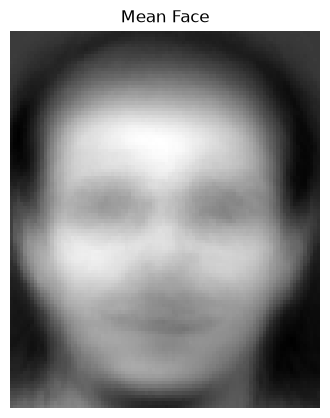

In [4]:
# Calculate the mean face using training data only
mean_face = np.mean(X_train, axis=0)

# Center training and testing images using the same mean
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)

# Visualize the mean face
plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(image_shape), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

## PCA Using Singular Value Decomposition (SVD)

Singular Value Decomposition (SVD) factorizes the centered training matrix into three matrices:

\[
X_c = U\Sigma V^T
\]

Here, \(X_c\) is the mean-centered training matrix, \(U\) contains the left singular vectors, \(\Sigma\) contains the singular values, and \(V^T\) contains the principal directions as rows.

The principal directions are ordered by decreasing variance. The variance explained by component \(j\) is calculated as:

\[
\lambda_j = \frac{\sigma_j^2}{n-1}
\]

where \(\sigma_j\) is its singular value and \(n\) is the number of training images.

We use NumPy's SVD implementation to calculate these values without using Scikit-learn PCA.

In [5]:
# Apply SVD to the centered training data
U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Calculate variance explained by each component
n_train = X_train_centered.shape[0]

explained_variances = singular_values**2 / (n_train - 1)

# Calculate the proportion of total variance explained
explained_variance_ratio = (
    explained_variances / explained_variances.sum()
)

# Calculate cumulative explained variance
cumulative_explained_variance = np.cumsum(
    explained_variance_ratio
)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("Vt shape:", Vt.shape)

print("\nFirst 10 singular values:")
print(singular_values[:10])

print("\nFirst 10 explained variance ratios:")
print(explained_variance_ratio[:10])

U shape: (320, 320)
Singular values shape: (320,)
Vt shape: (320, 10304)

First 10 singular values:
[30316.4678745  25696.35533448 18679.49560166 16672.44779228
 16070.4941535  13195.97059758 11308.61189939 10994.80581333
  9978.59408806  9693.04198094]

First 10 explained variance ratios:
[0.17940463 0.12889009 0.06810935 0.05425943 0.05041211 0.03399062
 0.0249629  0.02359672 0.01943637 0.01833989]


### Selecting Principal Components Using Explained Variance

We select the smallest number of principal components whose cumulative explained variance reaches at least 90%.

This reduces the number of features while retaining most of the variation present in the training images.

In [6]:
# Minimum number of components needed for 90% variance
k90 = np.searchsorted(
    cumulative_explained_variance,
    0.90
) + 1

# Also calculate the number needed for 95%
k95 = np.searchsorted(
    cumulative_explained_variance,
    0.95
) + 1

print("Components needed for at least 90% variance:", k90)
print(
    "Variance retained:",
    cumulative_explained_variance[k90 - 1]
)

print("\nComponents needed for at least 95% variance:", k95)
print(
    "Variance retained:",
    cumulative_explained_variance[k95 - 1]
)

Components needed for at least 90% variance: 98
Variance retained: 0.9005854818500819

Components needed for at least 95% variance: 162
Variance retained: 0.9503489620201554


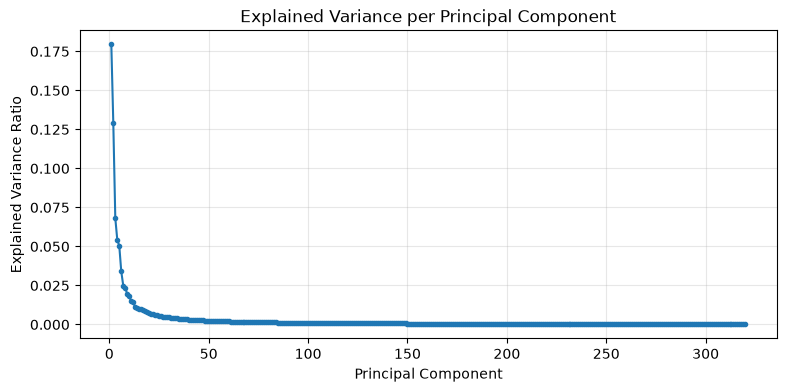

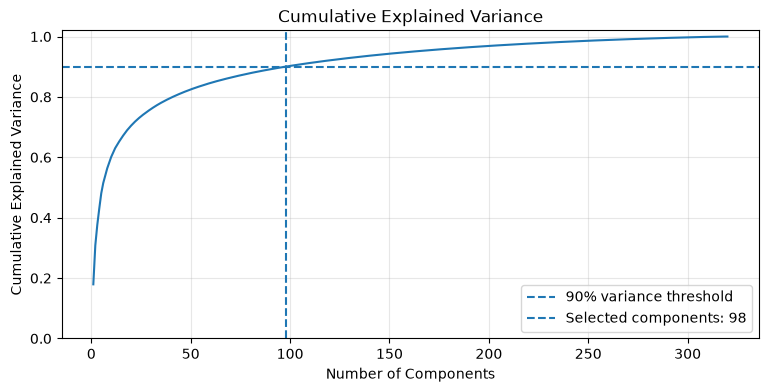

In [7]:
# Individual explained variance
plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio,
    marker="."
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance per Principal Component")
plt.grid(True, alpha=0.3)
plt.show()


# Cumulative explained variance
plt.figure(figsize=(9, 4))

plt.plot(
    np.arange(1, len(cumulative_explained_variance) + 1),
    cumulative_explained_variance
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance threshold"
)

plt.axvline(
    x=k90,
    linestyle="--",
    label=f"Selected components: {k90}"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### 1 -> The first few principal components capture much more variance than later components. The curve falls quickly, then becomes nearly flat.

#### This tells us that many components contribute only a small amount of additional variance.


#### 2 -> vertical line indicates 98 components, and the horizontal line indicates the 90% target.

#### Therefore, the smallest number of components reaching at least 90% variance is 98,

### PCA Using Eigen-Decomposition

Eigen-decomposition provides another way to calculate principal directions. For computational efficiency, we form the Gram matrix from the centered training data and calculate its eigenvalues and eigenvectors using NumPy's `eigh` function.

The nonzero eigenvalues of this Gram matrix correspond to the squared singular values obtained from SVD. We compare the leading principal directions from both methods. Since eigenvectors may differ in sign while representing the same direction, we compare the absolute dot products of corresponding directions.

In [8]:
# Construct the Gram matrix
G = X_train_centered @ X_train_centered.T

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(G)

# Sort eigenvalues in descending order
order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Keep only positive eigenvalues
positive = eigenvalues > 1e-10

eigenvalues = eigenvalues[positive]
eigenvectors = eigenvectors[:, positive]

# Convert Gram-matrix eigenvectors into pixel-space directions
V_eigen = (
    X_train_centered.T @ eigenvectors
) / np.sqrt(eigenvalues)[None, :]

# Compare the first 10 directions with SVD
num_compare = min(10, len(eigenvalues), Vt.shape[0])

agreement = np.abs(
    np.sum(
        V_eigen[:, :num_compare] * Vt[:num_compare].T,
        axis=0
    )
)

print("Gram matrix shape:", G.shape)

print("\nFirst 10 eigenvalues:")
print(eigenvalues[:10])

print("\nFirst 10 squared singular values:")
print(singular_values[:10] ** 2)

print("\nAbsolute direction agreement:")
print(np.round(agreement, 6))

Gram matrix shape: (320, 320)

First 10 eigenvalues:
[9.19088224e+08 6.60302677e+08 3.48923556e+08 2.77970515e+08
 2.58260782e+08 1.74133640e+08 1.27884703e+08 1.20885755e+08
 9.95723400e+07 9.39550628e+07]

First 10 squared singular values:
[9.19088224e+08 6.60302677e+08 3.48923556e+08 2.77970515e+08
 2.58260782e+08 1.74133640e+08 1.27884703e+08 1.20885755e+08
 9.95723400e+07 9.39550628e+07]

Absolute direction agreement:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Creating the Reduced PCA Representation

We retain the first 98 principal directions because they explain at least 90% of the variance in the training data. Each centered image is projected onto these directions to obtain its lower-dimensional representation.

The same PCA directions and training mean are used for both training and test images. This ensures that both datasets are represented in the same feature space without using test data to learn the PCA transformation.

In [9]:
# Select the first k90 principal directions
W = Vt[:k90].T

# Project training and testing data into PCA space
Z_train = X_train_centered @ W
Z_test = X_test_centered @ W

print("Number of selected components:", k90)
print("PCA basis shape:", W.shape)
print("Reduced training representation:", Z_train.shape)
print("Reduced testing representation:", Z_test.shape)

print(
    "Original features per image:", X_train.shape[1]
)
print(
    "Reduced features per image:", Z_train.shape[1]
)

Number of selected components: 98
PCA basis shape: (10304, 98)
Reduced training representation: (320, 98)
Reduced testing representation: (80, 98)
Original features per image: 10304
Reduced features per image: 98


## Part C: Eigenfaces and Image Reconstruction

The principal directions obtained from PCA can be reshaped into the original image dimensions to visualize eigenfaces. These eigenfaces represent patterns of variation learned from the training images rather than actual individual faces.

We then reconstruct test images using their reduced PCA representations. Comparing the reconstructed images with the originals helps us understand how dimensionality reduction affects image quality.

Finally, we calculate the mean squared reconstruction error and compare the number of values required to represent an original image with the number of PCA coefficients required for its reduced representation.

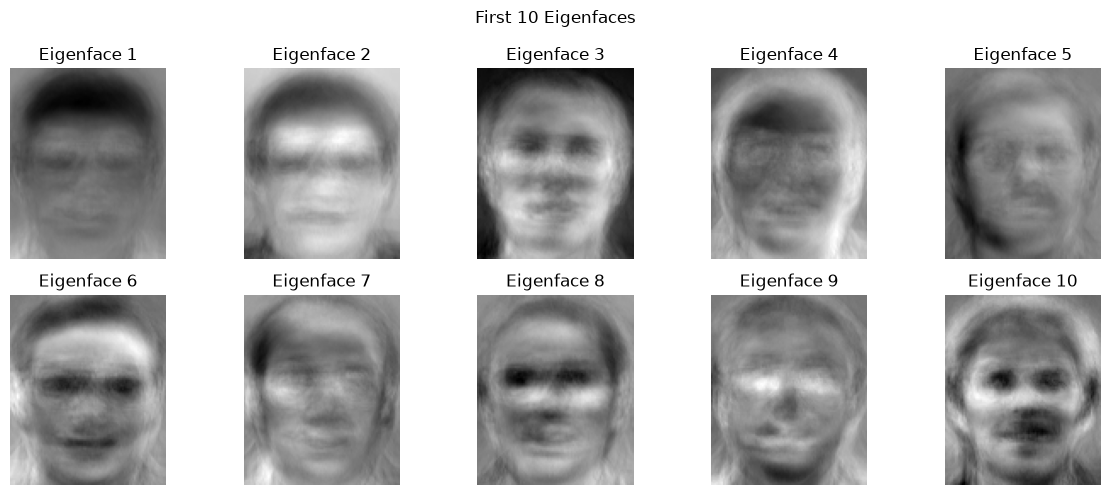

In [10]:
n_show = min(10, k90)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()[:n_show]):
    eigenface = W[:, i].reshape(image_shape)

    limit = np.max(np.abs(eigenface))

    ax.imshow(
        eigenface,
        cmap="gray",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 Eigenfaces")
plt.tight_layout()
plt.show()

### Reconstruct the centered test images, then restore the mean
X_test_reconstructed = Z_test @ W.T + mean_face

print("Original test data shape:", X_test.shape)
print("Reconstructed test data shape:", X_test_reconstructed.shape)

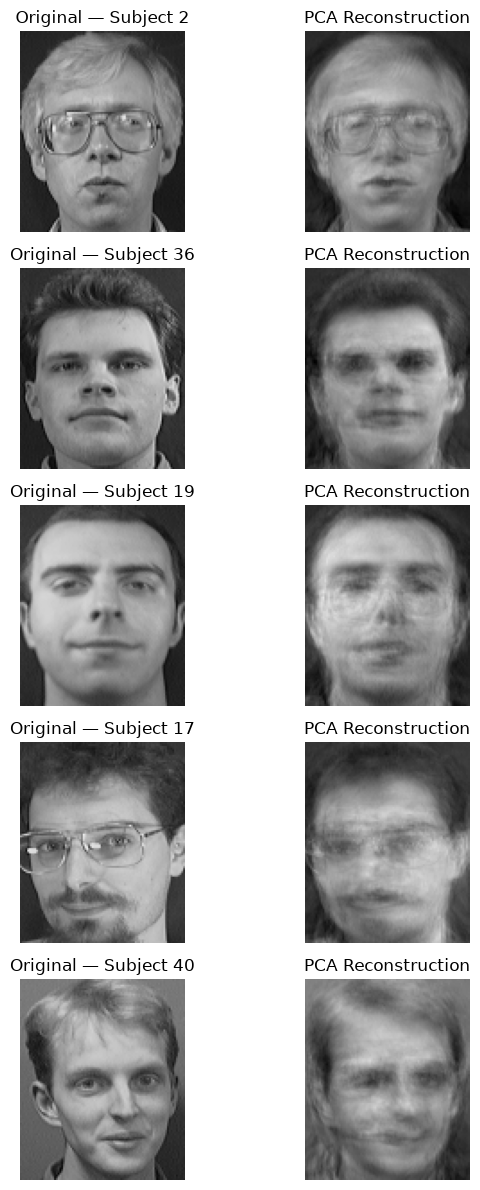

In [13]:
sample_count = 5

fig, axes = plt.subplots(sample_count, 2, figsize=(7, 12))

for i in range(sample_count):
    original = X_test[i].reshape(image_shape)
    reconstructed = X_test_reconstructed[i].reshape(image_shape)

    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Original — Subject {y_test[i]}")

    axes[i, 1].imshow(
        np.clip(reconstructed, 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[i, 1].set_title("PCA Reconstruction")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [14]:
mse = np.mean((X_test - X_test_reconstructed) ** 2)

print("Mean squared reconstruction error:", round(mse, 3))
print("Original features per image:", X_test.shape[1])
print("Reduced features per image:", Z_test.shape[1])

reduction = (1 - Z_test.shape[1] / X_test.shape[1]) * 100
print("Per-image feature reduction:", round(reduction, 2), "%")

Mean squared reconstruction error: 329.983
Original features per image: 10304
Reduced features per image: 98
Per-image feature reduction: 99.05 %


### Observations: Eigenfaces and Image Reconstruction

The principal components were reshaped into eigenfaces to visualize the major patterns of variation learned from the training images. Test images were reconstructed using their PCA representations and the mean face calculated from the training data.

The mean squared reconstruction error was **329.983**. The representation was reduced from 10,304 pixel values to 98 PCA coefficients per image, representing a **99.05% reduction in per-image feature count**.

The reconstruction demonstrates the trade-off between compact representation and image detail. PCA retains directions with the highest variance, but some information is lost when components are discarded. The reported reconstruction error measures pixel-level differences; it does not directly measure face-recognition accuracy.

## Part D: Face Recognition Using Similarity Matching

In this part, we identify test faces by comparing their reduced PCA representations with those of the training images.

For each test image, we calculate the Euclidean distance to every training image in PCA space. The training image with the smallest distance is selected as the nearest match, and its subject label becomes the predicted identity.

We evaluate recognition performance using test accuracy and inspect selected predictions to understand the strengths and limitations of similarity-based matching.

In [15]:
# Calculate Euclidean distances between test and training PCA features
distances = np.sqrt(
    np.sum(
        (Z_test[:, np.newaxis, :] - Z_train[np.newaxis, :, :]) ** 2,
        axis=2
    )
)

# Find the nearest training image for each test image
nearest_indices = np.argmin(distances, axis=1)

# Predict the subject label of the nearest training image
y_pred_nearest = y_train[nearest_indices]

# Calculate recognition accuracy
correct = np.sum(y_pred_nearest == y_test)
accuracy = correct / len(y_test)

print("Correct predictions:", correct, "out of", len(y_test))
print("Nearest-neighbor recognition accuracy:", round(accuracy * 100, 2), "%")

Correct predictions: 76 out of 80
Nearest-neighbor recognition accuracy: 95.0 %


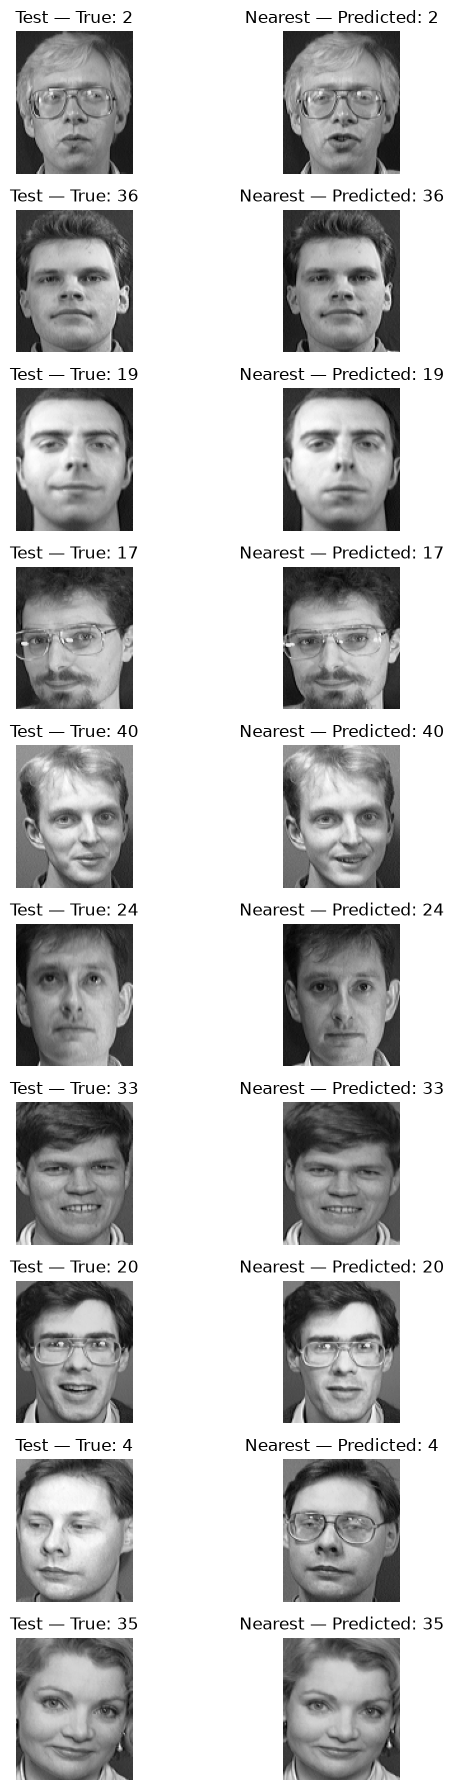

Incorrectly classified test images:
Test index 11: true subject = 28, predicted subject = 37
Test index 14: true subject = 10, predicted subject = 38
Test index 24: true subject = 39, predicted subject = 22
Test index 38: true subject = 5, predicted subject = 40


In [16]:
sample_count = 10

fig, axes = plt.subplots(sample_count, 2, figsize=(7, 18))

for i in range(sample_count):
    train_idx = nearest_indices[i]

    axes[i, 0].imshow(
        X_test[i].reshape(image_shape),
        cmap="gray"
    )
    axes[i, 0].set_title(f"Test — True: {y_test[i]}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        X_train[train_idx].reshape(image_shape),
        cmap="gray"
    )
    axes[i, 1].set_title(f"Nearest — Predicted: {y_pred_nearest[i]}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("Incorrectly classified test images:")

for i in range(len(y_test)):
    if y_pred_nearest[i] != y_test[i]:
        print(
            f"Test index {i}: true subject = {y_test[i]}, "
            f"predicted subject = {y_pred_nearest[i]}"
        )

### Results: PCA-Based Nearest-Neighbor Recognition

The nearest-neighbor method achieved **95.00% test accuracy**, correctly identifying 76 out of 80 test images. Four test images were incorrectly classified.

For each test image, Euclidean distance was calculated between its PCA representation and the representations of all training images. The subject label of the closest training image was used as the predicted identity.

These results show that the reduced PCA representation retains useful information for face recognition. However, the result is based on one train-test split and does not guarantee the same accuracy on other splits.

## Part E: Traditional Machine-Learning Classifiers

In this part, we train traditional machine-learning classifiers using the PCA-reduced training data and evaluate them on the test data.

We compare K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Logistic Regression with the nearest-neighbor similarity baseline. All classifiers use the same PCA features and train-test split to make the comparison consistent.

We report test accuracy to compare the recognition performance of the different approaches.

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

classifiers = {
    "KNN (3 neighbors)": KNeighborsClassifier(n_neighbors=3),
    "SVM (RBF kernel)": SVC(kernel="rbf", C=10, gamma="scale"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    )
}

results = {
    "PCA Nearest Neighbor": accuracy_score(y_test, y_pred_nearest)
}

predictions = {}

for name, model in classifiers.items():
    model.fit(Z_train, y_train)
    predictions[name] = model.predict(Z_test)
    results[name] = accuracy_score(y_test, predictions[name])

print("Classifier comparison")
print("-" * 42)

for name, score in results.items():
    print(f"{name:25s}: {score * 100:.2f}%")

Classifier comparison
------------------------------------------
PCA Nearest Neighbor     : 95.00%
KNN (3 neighbors)        : 91.25%
SVM (RBF kernel)         : 96.25%
Logistic Regression      : 95.00%


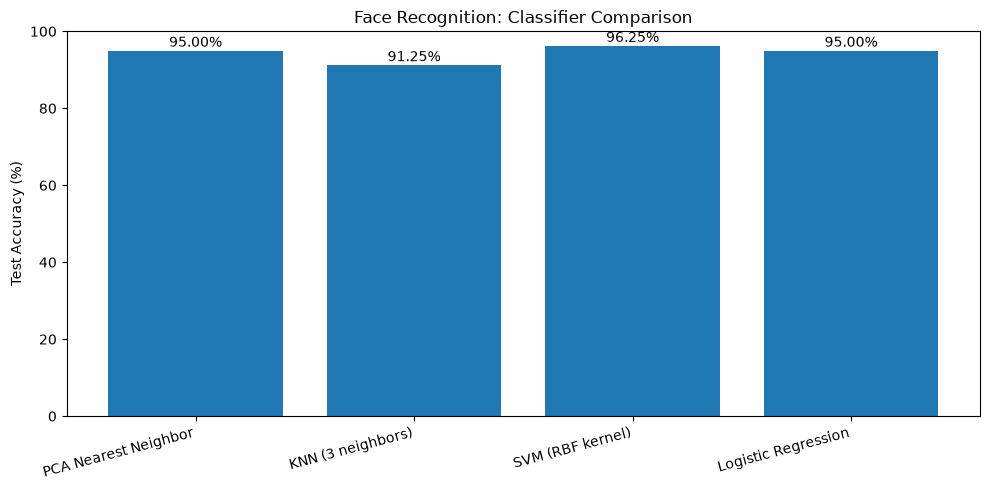

In [18]:
method_names = list(results.keys())
accuracy_values = [score * 100 for score in results.values()]

plt.figure(figsize=(10, 5))
bars = plt.bar(method_names, accuracy_values)

plt.ylabel("Test Accuracy (%)")
plt.title("Face Recognition: Classifier Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")

for bar, score in zip(bars, accuracy_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Results and Comparison of Face Recognition Methods

The PCA nearest-neighbor baseline achieved 95.00% test accuracy. K-Nearest Neighbors (KNN) with three neighbors achieved 91.25%, Support Vector Machine (SVM) with an RBF kernel achieved 96.25%, and Logistic Regression achieved 95.00%.

Among the evaluated methods, SVM performed best, correctly classifying 77 out of 80 test images. The PCA nearest-neighbor baseline and Logistic Regression each achieved 76 correct predictions, while KNN achieved 73.

The results show that traditional classifiers can use PCA-reduced features effectively for face recognition. SVM performed best on this particular train-test split, although further experiments with component counts and model settings would be needed to determine whether this improvement is consistent.

In [19]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

component_counts = sorted(set([25, 50, k90, 150, 250]))
component_counts = [
    k for k in component_counts
    if 1 <= k <= len(singular_values)
]

experiment_results = []

for k in component_counts:
    W_k = Vt[:k].T

    Z_train_k = X_train_centered @ W_k
    Z_test_k = X_test_centered @ W_k

    # PCA nearest-neighbor baseline
    distances_k = np.sum(
        (Z_test_k[:, None, :] - Z_train_k[None, :, :]) ** 2,
        axis=2
    )

    nearest_k = np.argmin(distances_k, axis=1)
    pred_nearest_k = y_train[nearest_k]

    # KNN classifier
    knn_k = KNeighborsClassifier(n_neighbors=3)
    knn_k.fit(Z_train_k, y_train)
    pred_knn_k = knn_k.predict(Z_test_k)

    # SVM classifier
    svm_k = SVC(kernel="rbf", C=10, gamma="scale")
    svm_k.fit(Z_train_k, y_train)
    pred_svm_k = svm_k.predict(Z_test_k)

    experiment_results.append({
        "Components": k,
        "Variance retained (%)":
            cumulative_explained_variance[k - 1] * 100,
        "Nearest Neighbor (%)":
            accuracy_score(y_test, pred_nearest_k) * 100,
        "KNN (%)":
            accuracy_score(y_test, pred_knn_k) * 100,
        "SVM (%)":
            accuracy_score(y_test, pred_svm_k) * 100
    })

import pandas as pd

experiment_table = pd.DataFrame(experiment_results)
print(experiment_table.round(2).to_string(index=False))

 Components  Variance retained (%)  Nearest Neighbor (%)  KNN (%)  SVM (%)
         25                  73.57                 95.00    92.50    96.25
         50                  82.48                 96.25    92.50    97.50
         98                  90.06                 95.00    91.25    96.25
        150                  94.31                 95.00    92.50    96.25
        250                  98.60                 95.00    93.75    97.50


### Effect of PCA Component Count on Recognition Accuracy

We evaluated nearest-neighbor matching, KNN, and SVM using 25, 50, 98, 150, and 250 principal components.

SVM achieved the highest observed accuracy of **97.50%** with both 50 and 250 components. With 50 components, it retained 82.48% of the training variance while reducing the representation from 10,304 pixel values to 50 coefficients per image.

The 250-component representation retained 98.60% of the variance and achieved the same SVM accuracy on this test split. Therefore, increasing the number of components did not improve SVM accuracy beyond the result obtained with 50 components.

These results suggest that a compact representation can be effective for face recognition. However, the best component count may vary with the data split and model settings. Further validation would be needed before concluding that 50 components are generally optimal.

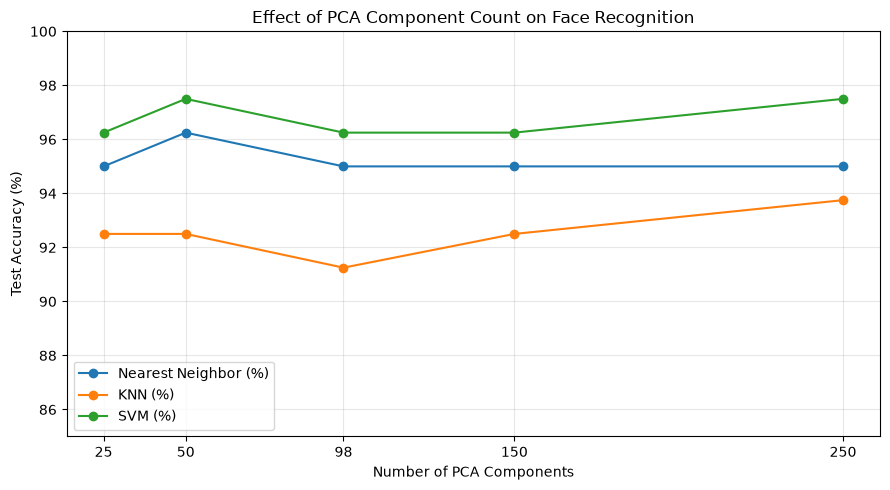

In [20]:
plt.figure(figsize=(9, 5))

for metric in [
    "Nearest Neighbor (%)",
    "KNN (%)",
    "SVM (%)"
]:
    plt.plot(
        experiment_table["Components"],
        experiment_table[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Number of PCA Components")
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of PCA Component Count on Face Recognition")
plt.xticks(experiment_table["Components"])
plt.ylim(85, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Final Results and Comparison

The following table summarizes the performance of the evaluated face-recognition methods on the same test set of 80 images.

| Method | PCA Components | Correct Predictions | Test Accuracy |
|---|---:|---:|---:|
| PCA Nearest Neighbor | 98 | 76/80 | 95.00% |
| K-Nearest Neighbors (3 neighbors) | 98 | 73/80 | 91.25% |
| Support Vector Machine (RBF) | 98 | 77/80 | 96.25% |
| Logistic Regression | 98 | 76/80 | 95.00% |

The SVM classifier achieved the highest accuracy among these four initial configurations. In the component-count experiment, SVM achieved 97.50% accuracy with both 50 and 250 components. These results are specific to the current train-test split.

## Conclusion

In this assignment, face images from the AT&T/ORL dataset were represented as numerical feature vectors and processed using Principal Component Analysis (PCA). Each grayscale image contained 10,304 pixel features. PCA was implemented using NumPy linear algebra, with SVD and eigen-decomposition producing matching leading principal directions.

Using the cumulative explained-variance criterion, 98 principal components retained approximately 90.06% of the training variance. This reduced the per-image feature count by approximately 99.05%. Eigenfaces were visualized, and test images were reconstructed with a mean squared error of 329.983.

The PCA nearest-neighbor baseline achieved 95.00% test accuracy. Among the initial classifier configurations, SVM achieved 96.25%, KNN achieved 91.25%, and Logistic Regression achieved 95.00%. In the component-count experiment, SVM achieved 97.50% with both 50 and 250 components.

Overall, the experiments demonstrate that PCA can create compact image representations while retaining useful information for face recognition. However, explained variance and classification accuracy measure different properties, and the best component count depends on the recognition method and evaluation setup. These conclusions are based on one fixed train-test split and would benefit from further validation.

In [21]:
experiment_table.round(2)

,Components,Variance retained (%),Nearest Neighbor (%),KNN (%),SVM (%)
0,25,73.57,95.00,92.50,96.25
1,50,82.48,96.25,92.50,97.50
2,98,90.06,95.00,91.25,96.25
3,150,94.31,95.00,92.50,96.25
4,250,98.60,95.00,93.75,97.50
